# **Exp 2 – Hyperparameter-Tuned Random Forest | OOF-Based Threshold Optimization**

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using class_weight='balanced'.
3. RandomizedSearchCV with 5-Fold Stratified CV is used to find the best hyperparameters based on PR-AUC.
4. Out-of-Fold (OOF) probabilities are generated using the best model.
5. OOF probabilities are used to find the best classification threshold based on F1 Score.
6. The selected threshold is applied to train and test probabilities to generate:
   0 = Retained | 1 = Churned.
7. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
8. Feature importance is analysed to identify the most influential features.


## 0. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict,
    cross_validate
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. Separate Features and Target

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64


## 2. Train-Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (11684, 104)
X_test: (2922, 104)


## 3. Identify Categorical and Numerical Columns

In [5]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", len(numerical_cols))


Categorical columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical columns: 101


## 4. Preprocessing Pipeline

In [6]:
categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

## 5. Regularized Random Forest Pipeline

In [7]:
rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

## 6. Stratified Cross Validation

In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 7. Hyperparameter Search Space

In [9]:
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

## 8. Randomized Search CV

In [10]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 9. Fit Randomized Search

In [11]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [2, 5, ...], 'model__min_samples_split': [5, 10, ...], ...}"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 10. Best Hyperparameters

In [12]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV PR-AUC:
0.30554474446608343


## 11. Best Random Forest Model

In [13]:
best_rf_pipeline = random_search.best_estimator_

## 12. Randomized Search Results

In [14]:
search_results_df = pd.DataFrame(
    random_search.cv_results_
)

search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

print(
    search_results_df[
        [
            'param_model__n_estimators',
            'param_model__max_depth',
            'param_model__min_samples_split',
            'param_model__min_samples_leaf',
            'param_model__max_features',
            'mean_test_score',
            'std_test_score'
        ]
    ].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_test_score  std_test_score
                       500                   None                               5                              5                       0.5           0.3055          0.0220
                       300                   None                              30                             10                       0.5           0.2914          0.0223
                       300                     15                              30                             15                       0.5           0.2857          0.0205
                       200                     15                              20                              2                       0.5           0.2823          0.0259
                       300                     10                              20             

## 13. Generate Out-of-Fold Probabilities

In [15]:
y_prob_oof = cross_val_predict(
    best_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

## 14. Precision-Recall Curve

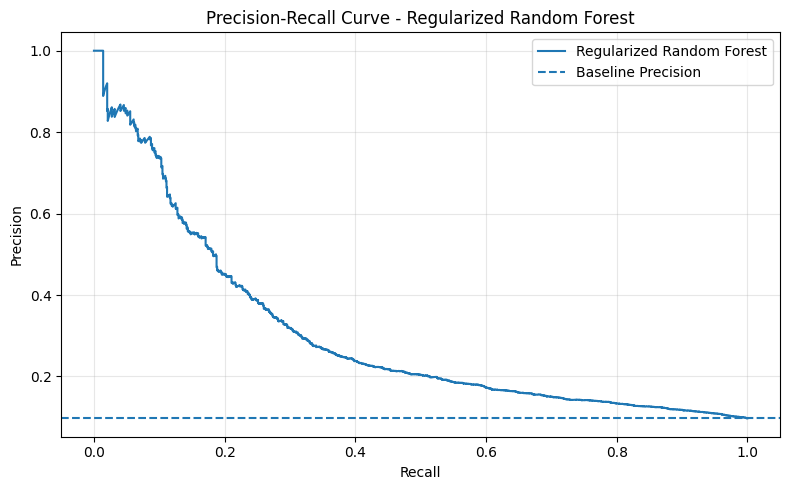

In [16]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_train,
    y_prob_oof
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label='Regularized Random Forest'
)

plt.axhline(
    y=y_train.mean(),
    linestyle='--',
    label='Baseline Precision'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Fine-Grained Threshold Analysis

In [17]:
threshold_values = np.arange(0.05, 0.56, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_oof >= threshold).astype(int)

    precision_value = precision_score(
        y_train,
        y_pred,
        zero_division=0
    )

    recall_value = recall_score(
        y_train,
        y_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_train,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_value,
        'Recall': recall_value,
        'F1 Score': f1_value
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1024  0.9780    0.1854
      0.06     0.1048  0.9674    0.1892
      0.07     0.1082  0.9577    0.1944
      0.08     0.1113  0.9374    0.1990
      0.09     0.1147  0.9181    0.2039
      0.10     0.1187  0.8952    0.2096
      0.11     0.1243  0.8687    0.2174
      0.12     0.1276  0.8317    0.2213
      0.13     0.1330  0.8044    0.2283
      0.14     0.1391  0.7762    0.2359
      0.15     0.1426  0.7322    0.2387
      0.16     0.1492  0.7022    0.2461
      0.17     0.1570  0.6705    0.2545
      0.18     0.1639  0.6405    0.2610
      0.19     0.1696  0.6079    0.2652
      0.20     0.1795  0.5885    0.2751
      0.21     0.1846  0.5542    0.2770
      0.22     0.1955  0.5313    0.2858
      0.23     0.2035  0.5031    0.2898
      0.24     0.2126  0.4731    0.2934
      0.25     0.2194  0.4432    0.2935
      0.26     0.2278  0.4176    0.2948
      0.27     0.2418  0.3965    0.30

## 16. Threshold Performance Visualization

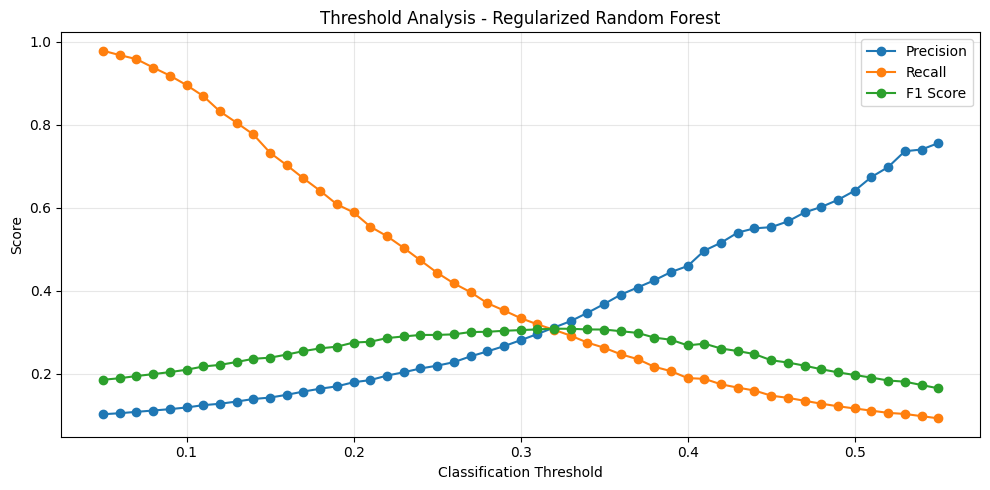

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Select Best Threshold

In [19]:
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)


==== BEST THRESHOLD ====
Best Threshold: 0.32000000000000006
Threshold    0.320000
Precision    0.311211
Recall       0.305727
F1 Score     0.308444
Name: 27, dtype: float64


## 18. Train Predictions

In [20]:
y_prob_train = best_rf_pipeline.predict_proba(
    X_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

## 19. Test Predictions

In [21]:
y_prob_test = best_rf_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

## 20. Define Metric Function

In [22]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 21. Train and Test Metrics

In [23]:
train_metrics = calc_metrics(
    y_train,
    y_pred_train,
    y_prob_train
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9844
Precision   : 0.8618
Recall      : 1.0000
F1 Score    : 0.9258
ROC-AUC     : 0.9998
PR-AUC      : 0.9982

==== TEST METRICS ====
Accuracy    : 0.8734
Precision   : 0.3486
Recall      : 0.3486
F1 Score    : 0.3486
ROC-AUC     : 0.7048
PR-AUC      : 0.3575


## 22. Confusion Matrix

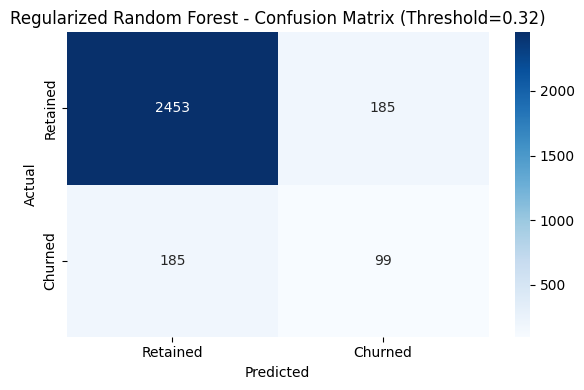

In [24]:
cm = confusion_matrix(
    y_test,
    y_pred_test
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    f'Regularized Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)

plt.tight_layout()
plt.show()

## 23. Classification Report

In [25]:
print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.93      0.93      2638
     Churned       0.35      0.35      0.35       284

    accuracy                           0.87      2922
   macro avg       0.64      0.64      0.64      2922
weighted avg       0.87      0.87      0.87      2922



## 24. Cross Validation Performance

In [26]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_train,
    y_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

## 25. Cross Validation Train Scores

In [27]:
print("\n==== CV TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CV TRAIN SCORES ====
train_Accuracy - Mean: 0.9991, Std: 0.0002
train_Precision - Mean: 0.9915, Std: 0.0023
train_Recall - Mean: 0.9989, Std: 0.0010
train_F1 - Mean: 0.9952, Std: 0.0013
train_ROC_AUC - Mean: 0.9999, Std: 0.0001
train_PR_AUC - Mean: 0.9986, Std: 0.0008


## 26. Cross Validation Validation Scores

In [28]:
print("\n==== CV VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CV VALIDATION SCORES ====
test_Accuracy - Mean: 0.9078, Std: 0.0015
test_Precision - Mean: 0.6451, Std: 0.0539
test_Recall - Mean: 0.1163, Std: 0.0066
test_F1 - Mean: 0.1968, Std: 0.0099
test_ROC_AUC - Mean: 0.7071, Std: 0.0136
test_PR_AUC - Mean: 0.3055, Std: 0.0220


## 27. Feature Importance

In [29]:
rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20))


==== TOP 20 IMPORTANT FEATURES ====
                       Feature  Importance
0           margin_net_pow_ele    0.074831
1      forecast_meter_rent_12m    0.039289
2         cons_last_month_diff    0.033415
3       margin_per_consumption    0.031787
4          forecast_cons_ratio    0.029696
5   price_consumption_exposure    0.025809
6      price_power_interaction    0.025332
7             margin_per_power    0.024434
8                 months_activ    0.023009
9        consumption_per_power    0.021780
10           months_modif_prod    0.021040
11       cons_last_month_ratio    0.019972
12                     pow_max    0.019562
13          margin_per_product    0.019509
14          forecast_cons_diff    0.017981
15                    cons_12m    0.017880
16           forecast_cons_12m    0.017162
17     var_year_price_off_peak    0.016803
18             cons_last_month    0.016369
19   tenure_margin_interaction    0.015087


# **Observation:**

**Regularized Random Forest Classifier**

**1. Model Optimization**

- Applied Randomized/Grid Search with 25 hyperparameter combinations and 5-fold cross-validation.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **30.55%** (compared to baseline CV PR-AUC of 25.43%).

**Observation:**
    
- Hyperparameter tuning improved cross-validation PR-AUC.
- Regularization through minimum samples per leaf and split helps control model complexity.

**2. Model Performance – Test Data**

- Accuracy: **87.34%**
- Precision: **34.86%**
- Recall: **34.86%**
- F1 Score: **34.86%**
- ROC-AUC: **70.48%**
- PR-AUC: **35.75%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.55.
- Selected threshold: **0.32**, based on the highest F1 score in the threshold analysis.
- At threshold 0.32 (threshold validation):
  - Precision: 31.12%
  - Recall: 30.57%
  - F1 Score: 30.84%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.32)**

- True Negatives: 2,453
- False Positives: 185
- False Negatives: 185
- True Positives: 99

**Observation:**

- Model correctly identifies 99 churn customers out of 284.
- It misses 185 actual churn customers.
- False positives have reduced to 185.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 35.75% indicates improved churn identification compared to the baseline Random Forest (32.77%).

**6. Cross-Validation Results**

- Training scores remain almost perfect.
- Validation accuracy: 90.78%
- Validation precision: 64.51%
- Validation recall: 11.63%
- Validation F1: 19.68%
- Validation ROC-AUC: 70.71%
- Validation PR-AUC: 30.55%

**Observation:**

- Validation PR-AUC improved from 25.43% to 30.55%.
- However, validation recall remains very low.
- Large differences between training and validation scores indicate overfitting.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- cons_last_month_diff
- margin_per_consumption
- forecast_cons_ratio
- price_consumption_exposure
- price_power_interaction
- margin_per_power
- months_activ
- consumption_per_power

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- Their importance has increased compared to the baseline model.

**8. Model Comparison – Baseline vs Regularized Random Forest**

| Metric    | Baseline RF | Regularized RF |
| --------- | ----------- | -------------- |
| Accuracy  | 84.02%      | **87.34%**     |
| Precision | 26.72%      | **34.86%**     |
| Recall    | **36.97%**  | 34.86%         |
| F1 Score  | 31.02%      | **34.86%**     |
| ROC-AUC   | **70.76%**  | 70.48%         |
| PR-AUC    | 32.77%      | **35.75%**     |
| CV PR-AUC | 25.43%      | **30.55%**     |

**Observation:**

- Regularized Random Forest improves PR-AUC by 2.98 percentage points.
- Precision improves by 8.14 percentage points.
- F1 Score improves by 3.84 percentage points.
- Recall decreases slightly by 2.11 percentage points.
- ROC-AUC remains almost unchanged.

**Final Conclusion – Regularized Random Forest**

- Regularized Random Forest performs better overall than the baseline model.
- It achieves better PR-AUC, precision and F1 Score.
- However, recall has decreased slightly, and overfitting still exists.
- Hyperparameter tuning has improved model performance but has not fully solved the overfitting problem.

Better than Baseline

**Regularized Random Forest is currently the better model because it identifies churn customers with higher precision and achieves a better F1 Score and PR-AUC. We will use it as the current best-performing model for comparison with upcoming experiments.**

**Important note:** CV metrics use the default 0.50 threshold, while test metrics use the selected 0.32 threshold. Compare CV and test classification metrics cautiously.